# 합성 이미지 생성 v3

[v2 대비 변경 사항]
1. **palm_hand 배경 풀 확장**: 6장 → 42장 (Nano Banana 50장 생성 후 마스크 검수로 8장 폐기)
2. **MAX_PILL_AREA_POST**: 0.50 → 0.20 (거대 알약 컷 차단, 현실성 확보)
3. **palm_hand 마스크 활용 + 침식**: rembg 마스크에 50px 침식 → 손가락 끝/손목 끝 제거 → 알약이 손바닥 중앙 위주로 떨어짐 (실 사용자 사진 패턴 매칭)
4. **나머지 5개 카테고리 (dark, fabric, gray, marble, white)**: 균일 배경이라 무작위 배치 그대로
5. **출력 폴더 분리**: synthetic_v2 → synthetic_v3
6. **START_IDX = 0**: v3는 0부터 시작
7. **합성 양 7994장 (v2 동일)**: train 9:1 분할 후 train ~7188 + val 800

[변수 통제 = 합성 로직 변수 v2와 동일]
- 알약 개수 가중치 (1: 13.5%, 2: 42.9%, 3: 31.1%, 4: 12.4%)
- 양질 lognormal 크기 분포 (개수별 mean/std 분리)
- SIGMA_CLIP 2.0, MIN_PILLS 1, MARGIN 30
- random.seed(43), np.random.seed(43)
- 배경 카테고리 6개 + modulo 순환


## 1. 환경 설정

In [12]:
import os
import cv2
import random
import pickle
import numpy as np
from collections import Counter
from pathlib import Path
from PIL import Image

# 경로 설정 (v3)
BG_DIR        = Path(r"D:\pill_detection\synthetic_bg")
SYNTH_DIR     = Path(r"D:\pill_detection\synthetic_v3")
SYNTH_IMG_DIR = SYNTH_DIR / "images" / "train"
SYNTH_LBL_DIR = SYNTH_DIR / "labels" / "train"
CROPS_CACHE   = Path(r"D:\pill_detection\crops_cache.pkl")

SYNTH_IMG_DIR.mkdir(parents=True, exist_ok=True)
SYNTH_LBL_DIR.mkdir(parents=True, exist_ok=True)

# val 폴더도 미리 생성 (9:1 분할 후 사용)
(SYNTH_DIR / "images" / "val").mkdir(parents=True, exist_ok=True)
(SYNTH_DIR / "labels" / "val").mkdir(parents=True, exist_ok=True)

print(f"배경 폴더: {BG_DIR} (존재: {BG_DIR.exists()})")
print(f"피클 파일: {CROPS_CACHE} (존재: {CROPS_CACHE.exists()})")
print(f"출력 폴더: {SYNTH_DIR}")


배경 폴더: D:\pill_detection\synthetic_bg (존재: True)
피클 파일: D:\pill_detection\crops_cache.pkl (존재: True)
출력 폴더: D:\pill_detection\synthetic_v3


## 2. 합성 설정

In [13]:
IMG_W               = 976
IMG_H               = 1280
IMG_AREA            = IMG_W * IMG_H
N_SYNTH             = 7994            # ★ dry-run: 10 / 본 실행: 7994
START_IDX           = 0
MIN_PILLS           = 1
MAX_PILLS           = 4
MARGIN              = 30
MAX_PILL_AREA_POST  = 0.20          # v2: 0.50 → v3: 0.20 (현실성 확보)

# v3 신규: palm_hand 카테고리는 손 마스크 + 침식 활용
PALM_CATEGORIES     = {'palm_hand'}
PALM_MASK_DIR       = Path(r'D:\pill_detection\synthetic_bg\palm_hand_masks')
PALM_MASK_ERODE_PX  = 100            # 마스크 침식 — 손가락 끝/가장자리/손목 끝 제거

PILL_COUNT_WEIGHTS = {
    1: 0.135,
    2: 0.429,
    3: 0.311,
    4: 0.124,
}

PILL_SIZE_DIST = {
    1: {'mean': -0.68, 'std': 0.131},
    2: {'mean': -1.25, 'std': 0.585},
    3: {'mean': -1.45, 'std': 0.564},
    4: {'mean': -1.45, 'std': 0.564},
}

SIGMA_CLIP     = 2.0
MAX_SIZE_RETRY = 30

BG_CATEGORIES = [
    'dark_surface', 'fabric', 'gray_surface',
    'marble_tile', 'palm_hand', 'white_paper',
]

random.seed(43)
np.random.seed(43)

print(f"N_SYNTH = {N_SYNTH}")
print(f"START_IDX = {START_IDX}")
print(f"MAX_PILL_AREA_POST = {MAX_PILL_AREA_POST} (v2: 0.50)")
print(f"PALM 마스크 활용: {PALM_CATEGORIES}")
print(f"PALM_MASK_DIR: {PALM_MASK_DIR}")
print(f"PALM_MASK_ERODE_PX: {PALM_MASK_ERODE_PX}px (손가락 끝/손목 제거)")
assert PALM_MASK_DIR.exists(), f'마스크 폴더 없음: {PALM_MASK_DIR}'
n_masks = len(list(PALM_MASK_DIR.glob('palm_*_mask.png')))
print(f"마스크 파일 수: {n_masks}장")
print(f"이미지당 알약 {MIN_PILLS}~{MAX_PILLS}개 (양질 가중치)")


N_SYNTH = 7994
START_IDX = 0
MAX_PILL_AREA_POST = 0.2 (v2: 0.50)
PALM 마스크 활용: {'palm_hand'}
PALM_MASK_DIR: D:\pill_detection\synthetic_bg\palm_hand_masks
PALM_MASK_ERODE_PX: 100px (손가락 끝/손목 제거)
마스크 파일 수: 42장
이미지당 알약 1~4개 (양질 가중치)


## 3. 유틸 함수

In [14]:
def boxes_overlap(new_box, placed_boxes, img_area):
    """15% 이상 겹치면 충돌."""
    nx1, ny1, nx2, ny2 = new_box
    for bx1, by1, bx2, by2 in placed_boxes:
        ix1 = max(nx1, bx1); iy1 = max(ny1, by1)
        ix2 = min(nx2, bx2); iy2 = min(ny2, by2)
        if ix2 > ix1 and iy2 > iy1:
            inter = (ix2 - ix1) * (iy2 - iy1)
            new_area = (nx2 - nx1) * (ny2 - ny1)
            if inter / new_area > 0.15:
                return True
    return False


def sample_n_pills():
    """양질 분포 가중치로 알약 개수 샘플링."""
    keys = list(PILL_COUNT_WEIGHTS.keys())
    weights = list(PILL_COUNT_WEIGHTS.values())
    return random.choices(keys, weights=weights, k=1)[0]


def sample_target_size(n_pills, orig_w, orig_h):
    """
    양질 분포 기반 목표 크기 결정. 업스케일 허용.

    각인 학습을 위해 알약을 충분히 크게 합성하는 것이 우선.
    화질 저하는 LANCZOS 보간으로 어느 정도 보완.
    이미지 너비/높이를 벗어나는 경우 비율 유지하며 클리핑.
    """
    dist = PILL_SIZE_DIST[n_pills]
    mean, std = dist['mean'], dist['std']

    log_min = mean - SIGMA_CLIP * std
    log_max = mean + SIGMA_CLIP * std

    log_sample = np.random.normal(mean, std)
    log_sample = np.clip(log_sample, log_min, log_max)
    target_ratio = 10 ** log_sample

    orig_area_ratio = (orig_w * orig_h) / IMG_AREA
    scale = (target_ratio / orig_area_ratio) ** 0.5
    tw = max(10, int(orig_w * scale))
    th = max(10, int(orig_h * scale))

    # 이미지 영역 안에 들어가도록 클리핑 (비율 유지)
    max_w = IMG_W - 2 * MARGIN
    max_h = IMG_H - 2 * MARGIN
    if tw > max_w or th > max_h:
        clip_scale = min(max_w / tw, max_h / th)
        tw = max(10, int(tw * clip_scale))
        th = max(10, int(th * clip_scale))

    return tw, th

## 4. 피클 로드 (알약 누끼 7503개)

기존 `crops_cache.pkl` 그대로 사용. 항목 키: `img` / `class_idx` / `w` / `h`.

In [15]:
print(f"피클 로드 중... ({CROPS_CACHE.stat().st_size / (1024**3):.2f} GB)")
with open(CROPS_CACHE, "rb") as f:
    crops = pickle.load(f)

print(f"  → 총 {len(crops)}개 누끼")
print(f"  → 첫 원소 키: {list(crops[0].keys())}")

# 클래스별 인덱스 맵 (클래스 균등 샘플링)
class_map = {}
for i, c in enumerate(crops):
    class_map.setdefault(c["class_idx"], []).append(i)

print(f"  → 클래스 수: {len(class_map)}")
print(f"  → 클래스당 평균 누끼: {len(crops) / len(class_map):.1f}개")

피클 로드 중... (2.51 GB)
  → 총 7503개 누끼
  → 첫 원소 키: ['img', 'class_idx', 'w', 'h']
  → 클래스 수: 118
  → 클래스당 평균 누끼: 63.6개


## 5. 배경 이미지 로드 (카테고리별)

`BG_CATEGORIES` 에 명시된 6개 폴더만 검색. `_test`, `_texture_test` 같은 작업용 폴더 자동 제외.

In [16]:
bg_files = []
bg_categories = []

print(f"배경 카테고리별 이미지 수:")
for cat in BG_CATEGORIES:
    cat_dir = BG_DIR / cat
    if not cat_dir.exists():
        print(f"  [경고] {cat}: 폴더 없음 ({cat_dir})")
        continue
    cat_files = (
        list(cat_dir.glob("*.jpg")) +
        list(cat_dir.glob("*.jpeg")) +
        list(cat_dir.glob("*.png"))
    )
    bg_files.extend(cat_files)
    bg_categories.extend([cat] * len(cat_files))
    print(f"  {cat:>15}: {len(cat_files)}장")

print(f"\n총 배경 이미지 수: {len(bg_files)}장")

# v3: 침식 커널
erode_kernel = np.ones((PALM_MASK_ERODE_PX, PALM_MASK_ERODE_PX), np.uint8)

backgrounds = []
bg_masks = []
mask_coverage_log = []   # 침식 전후 커버리지 비교용

for p, cat in zip(bg_files, bg_categories):
    img = cv2.imread(str(p))
    if img is None:
        img = cv2.imdecode(np.fromfile(str(p), np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        print(f'  [경고] 로드 실패: {p.name}')
        continue
    img = cv2.resize(img, (IMG_W, IMG_H))
    backgrounds.append(img)

    if cat in PALM_CATEGORIES:
        mask_path = PALM_MASK_DIR / (p.stem + '_mask.png')
        if not mask_path.exists():
            print(f'  [경고] 마스크 없음: {mask_path.name} → 100% 흰 마스크로 폴백')
            mask = np.full((IMG_H, IMG_W), 255, dtype=np.uint8)
        else:
            mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
            if mask is None:
                mask = cv2.imdecode(np.fromfile(str(mask_path), np.uint8), cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (IMG_W, IMG_H), interpolation=cv2.INTER_NEAREST)
            mask = (mask > 128).astype(np.uint8) * 255

        # v3: 침식 적용
        coverage_before = (mask == 255).mean() * 100
        mask_eroded = cv2.erode(mask, erode_kernel, iterations=1)
        coverage_after = (mask_eroded == 255).mean() * 100
        mask_coverage_log.append((p.stem, coverage_before, coverage_after))

        # 침식 후 마스크가 너무 작으면 (< 5%) 침식 안 한 원본 사용 (폴백)
        if coverage_after < 5:
            print(f'  [폴백] {p.stem}: 침식 후 {coverage_after:.1f}% < 5% → 원본 마스크 사용 (침식 X)')
            bg_masks.append(mask)
        else:
            bg_masks.append(mask_eroded)
    else:
        bg_masks.append(None)

print(f"\n로드 완료: {len(backgrounds)}장 ({IMG_W}x{IMG_H} 리사이즈)")
print(f"  마스크 로드 (palm): {sum(1 for m in bg_masks if m is not None)}장")

# 침식 효과 통계
if mask_coverage_log:
    befores = [b for _, b, _ in mask_coverage_log]
    afters = [a for _, _, a in mask_coverage_log]
    print(f"\n침식 효과 ({PALM_MASK_ERODE_PX}px):")
    print(f"  침식 전 커버리지: mean {np.mean(befores):.1f}% / min {min(befores):.1f}% / max {max(befores):.1f}%")
    print(f"  침식 후 커버리지: mean {np.mean(afters):.1f}% / min {min(afters):.1f}% / max {max(afters):.1f}%")
    print(f"  평균 감소: {np.mean(befores) - np.mean(afters):.1f}pp")

from collections import Counter
cat_counter = Counter(bg_categories)
print(f"\n카테고리 비율:")
for cat, n in cat_counter.items():
    pct = n / len(bg_categories) * 100
    flag = ' ★ 마스크+침식' if cat in PALM_CATEGORIES else ''
    print(f"  {cat:>15}: {n:>3}장 ({pct:>4.1f}%){flag}")


배경 카테고리별 이미지 수:
     dark_surface: 42장
           fabric: 39장
     gray_surface: 51장
      marble_tile: 27장
        palm_hand: 42장
      white_paper: 24장

총 배경 이미지 수: 225장

로드 완료: 225장 (976x1280 리사이즈)
  마스크 로드 (palm): 42장

침식 효과 (100px):
  침식 전 커버리지: mean 54.5% / min 26.4% / max 100.0%
  침식 후 커버리지: mean 33.9% / min 10.0% / max 100.0%
  평균 감소: 20.6pp

카테고리 비율:
     dark_surface:  42장 (18.7%)
           fabric:  39장 (17.3%)
     gray_surface:  51장 (22.7%)
      marble_tile:  27장 (12.0%)
        palm_hand:  42장 (18.7%) ★ 마스크+침식
      white_paper:  24장 (10.7%)


## 6. palm dry-run 검증 (마스크 + 침식 확인)

본 합성 전 palm 카테고리 강제 합성으로 마스크 작동 확인.

**검증 포인트**:
- 알약이 손바닥 안 + 손가락 끝/손목 끝 회피
- mask_reject 카운트 (마스크 작동 증거)
- 알약 0개 이미지 (너무 많으면 침식 강도 줄여야 함)

통과 시 다음 섹션 (## 7. 합성 실행) 진행.


In [17]:
import shutil

PALM_TEST_DIR = SYNTH_DIR / 'palm_test'
PALM_TEST_IMG = PALM_TEST_DIR / 'images'
PALM_TEST_LBL = PALM_TEST_DIR / 'labels'
if PALM_TEST_DIR.exists():
    shutil.rmtree(PALM_TEST_DIR)
PALM_TEST_IMG.mkdir(parents=True, exist_ok=True)
PALM_TEST_LBL.mkdir(parents=True, exist_ok=True)

palm_indices = [i for i, c in enumerate(bg_categories) if c == 'palm_hand']
print(f'palm_hand 배경: {len(palm_indices)}장')

# bg_masks 침식 적용 검증
if palm_indices:
    cov_check = (bg_masks[palm_indices[0]] == 255).mean() * 100
    print(f'bg_masks[palm_001] 커버리지: {cov_check:.1f}% (PALM_MASK_ERODE_PX={PALM_MASK_ERODE_PX})')
    if PALM_MASK_ERODE_PX == 100 and cov_check > 25:
        print(f'  [경고] 100px 침식 기대치 ~12-15% 인데 너무 큼. 셀 10 재실행 필요')

random.seed(43)
np.random.seed(43)

success = 0
mask_reject = 0
no_pill_imgs = 0

for test_idx, bg_idx in enumerate(palm_indices):
    bg = backgrounds[bg_idx].copy()
    bg_mask = bg_masks[bg_idx]
    
    n_pills = sample_n_pills()
    placed_boxes = []
    labels = []

    for _ in range(n_pills):
        cls_idx = random.choice(list(class_map.keys()))
        crop_idx = random.choice(class_map[cls_idx])
        crop_info = crops[crop_idx]
        rgba = crop_info['img']
        orig_w, orig_h = rgba.size

        cw, ch = sample_target_size(n_pills, orig_w, orig_h)
        if (cw, ch) != (orig_w, orig_h):
            rgba = rgba.resize((cw, ch), Image.LANCZOS)

        x_min, x_max = MARGIN, IMG_W - cw - MARGIN
        y_min, y_max = MARGIN, IMG_H - ch - MARGIN

        for _ in range(30):
            px = random.randint(x_min, max(x_min + 1, x_max))
            py = random.randint(y_min, max(y_min + 1, y_max))
            new_box = (px, py, px + cw, py + ch)

            post_ratio = (cw * ch) / IMG_AREA
            if post_ratio > MAX_PILL_AREA_POST:
                continue
            if boxes_overlap(new_box, placed_boxes, IMG_AREA):
                continue
            
            cx_pixel = px + cw // 2
            cy_pixel = py + ch // 2
            if bg_mask[cy_pixel, cx_pixel] == 0:
                mask_reject += 1
                continue

            rgba_np = np.array(rgba)
            alpha = rgba_np[:, :, 3:4] / 255.0
            pill_rgb = rgba_np[:, :, :3][:, :, ::-1]
            roi = bg[py:py + ch, px:px + cw]
            blended = (pill_rgb * alpha + roi * (1 - alpha)).astype(np.uint8)
            bg[py:py + ch, px:px + cw] = blended

            placed_boxes.append(new_box)
            cx_n = (px + cw / 2) / IMG_W
            cy_n = (py + ch / 2) / IMG_H
            bw_n = cw / IMG_W
            bh_n = ch / IMG_H
            labels.append(f'{cls_idx} {cx_n:.6f} {cy_n:.6f} {bw_n:.6f} {bh_n:.6f}')
            break

    if not labels:
        no_pill_imgs += 1
        continue

    bg_stem = bg_files[bg_idx].stem
    fname = f'palm_test_{test_idx:03d}_{bg_stem}'
    cv2.imwrite(str(PALM_TEST_IMG / f'{fname}.jpg'), bg)
    with open(PALM_TEST_LBL / f'{fname}.txt', 'w') as f:
        f.write('\n'.join(labels))
    success += 1

print(f'\npalm 합성: {success}/{len(palm_indices)}장')
print(f'mask_reject: {mask_reject}회 (다른 위치 재시도)')
print(f'알약 0개 이미지: {no_pill_imgs}장')


palm_hand 배경: 42장
bg_masks[palm_001] 커버리지: 17.6% (PALM_MASK_ERODE_PX=100)

palm 합성: 37/42장
mask_reject: 156회 (다른 위치 재시도)
알약 0개 이미지: 5장


### palm dry-run 시각화 (12장)

회색 = 마스크 밖 (침식 후 알약 배치 X 영역) / 초록 = 알약 bbox


시각화 대상: 37장


C:\Users\user\AppData\Local\Temp\ipykernel_17188\2722942421.py:62: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2722942421.py:62: UserWarning: Glyph 52840 (\N{HANGUL SYLLABLE CIM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2722942421.py:62: UserWarning: Glyph 49885 (\N{HANGUL SYLLABLE SIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2722942421.py:62: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2722942421.py:62: UserWarning: Glyph 49353 (\N{HANGUL SYLLABLE SAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2722942421.py:62: UserWarning: Glyph 47560 (\N{HANGUL SYLLABLE MA}) missing from font

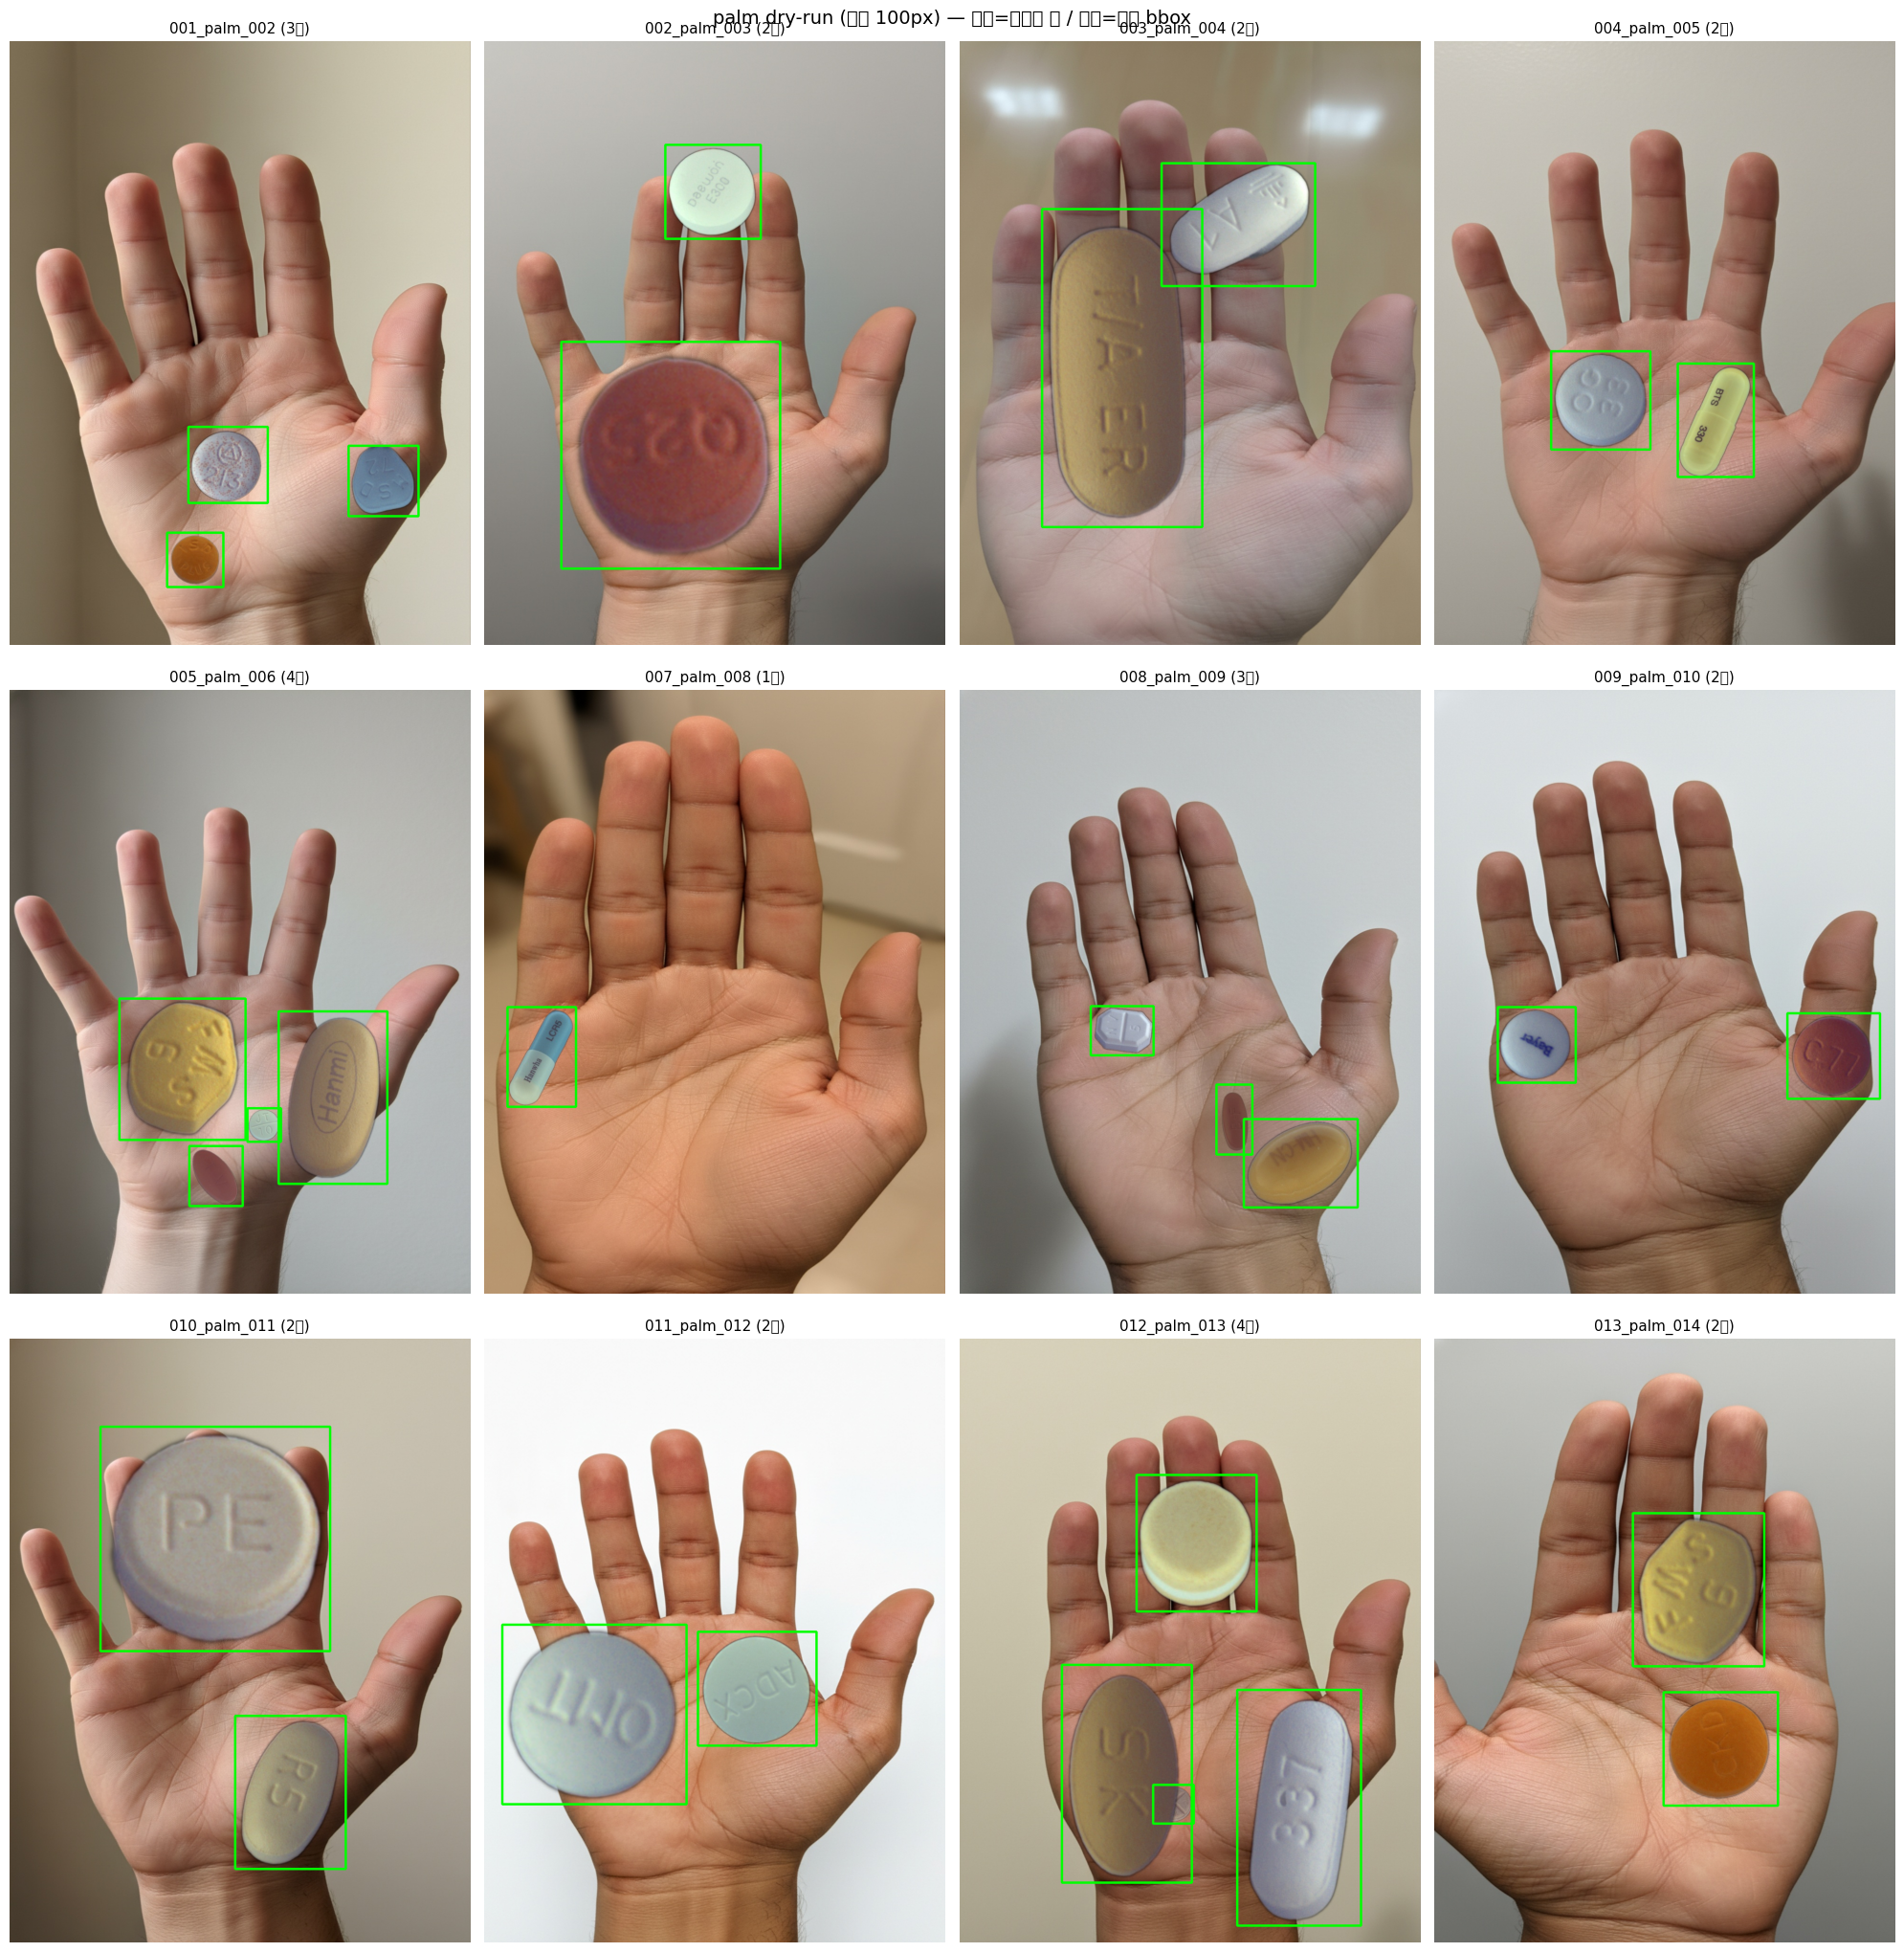

In [18]:
import matplotlib.pyplot as plt

palm_paths_test = sorted(PALM_TEST_IMG.glob('palm_test_*.jpg'))
print(f'시각화 대상: {len(palm_paths_test)}장')

N_SHOW = min(12, len(palm_paths_test))
show_paths = palm_paths_test[:N_SHOW]
cols, rows = 4, (N_SHOW + 3) // 4

erode_kernel = np.ones((PALM_MASK_ERODE_PX, PALM_MASK_ERODE_PX), np.uint8)

fig, axes = plt.subplots(rows, cols, figsize=(20, 7 * rows))
if rows == 1:
    axes = axes.reshape(1, -1)

for i, img_path in enumerate(show_paths):
    r, c = i // cols, i % cols
    ax = axes[r, c]

    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    parts = img_path.stem.split('_')
    bg_stem = '_'.join(parts[2:])
    
    mask_path = PALM_MASK_DIR / f'{bg_stem}_mask.png'
    if mask_path.exists():
        mask_raw = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        mask_raw = cv2.resize(mask_raw, (w, h), interpolation=cv2.INTER_NEAREST)
        mask_raw = (mask_raw > 128).astype(np.uint8) * 255
        mask_eroded = cv2.erode(mask_raw, erode_kernel, iterations=1)
        if (mask_eroded == 255).mean() < 0.05:
            mask = mask_raw
        else:
            mask = mask_eroded
        
        bg_only = mask < 128
        img[bg_only] = (img[bg_only] * 0.6 + np.array([100, 100, 100]) * 0.4).astype(np.uint8)
    
    lbl_path = PALM_TEST_LBL / (img_path.stem + '.txt')
    n_pills = 0
    with open(lbl_path) as f:
        for line in f:
            parts_l = line.strip().split()
            if len(parts_l) < 5:
                continue
            cls, cx, cy, bw, bh = parts_l[0], *map(float, parts_l[1:5])
            x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
            x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 4)
            n_pills += 1

    ax.imshow(img)
    ax.set_title(f'{bg_stem} ({n_pills}개)', fontsize=11)
    ax.axis('off')

for i in range(N_SHOW, rows * cols):
    r, c = i // cols, i % cols
    axes[r, c].axis('off')

plt.suptitle(f'palm dry-run (침식 {PALM_MASK_ERODE_PX}px) — 회색=마스크 밖 / 초록=알약 bbox', fontsize=14)
plt.tight_layout()
plt.show()


## 7. 합성 실행 (본 실행)


In [19]:
print(f"\n합성 시작 (총 {N_SYNTH}장 목표)")
print(f"  배경 {len(backgrounds)}개 → 한 배경당 평균 {N_SYNTH / len(backgrounds):.1f}회 사용\n")

success = 0
palm_count = 0
palm_mask_reject = 0   # 마스크 밖이라 reject된 시도 카운트

for img_idx in range(START_IDX, START_IDX + N_SYNTH):
    bg_idx = img_idx % len(backgrounds)
    bg = backgrounds[bg_idx].copy()
    bg_cat = bg_categories[bg_idx]
    bg_mask = bg_masks[bg_idx]   # palm일 때만 array, 아니면 None
    is_palm = bg_cat in PALM_CATEGORIES
    if is_palm:
        palm_count += 1
    
    n_pills = sample_n_pills()
    placed_boxes = []
    labels = []

    for _ in range(n_pills):
        cls_idx = random.choice(list(class_map.keys()))
        crop_idx = random.choice(class_map[cls_idx])
        crop_info = crops[crop_idx]
        rgba = crop_info["img"]
        orig_w, orig_h = rgba.size

        cw, ch = sample_target_size(n_pills, orig_w, orig_h)
        if (cw, ch) != (orig_w, orig_h):
            rgba = rgba.resize((cw, ch), Image.LANCZOS)

        # 위치 후보 영역 (palm/non-palm 동일하게 전체 이미지)
        x_min, x_max = MARGIN, IMG_W - cw - MARGIN
        y_min, y_max = MARGIN, IMG_H - ch - MARGIN

        for _ in range(30):
            px = random.randint(x_min, max(x_min + 1, x_max))
            py = random.randint(y_min, max(y_min + 1, y_max))
            new_box = (px, py, px + cw, py + ch)

            post_ratio = (cw * ch) / IMG_AREA
            if post_ratio > MAX_PILL_AREA_POST:
                continue
            if boxes_overlap(new_box, placed_boxes, IMG_AREA):
                continue

            # v3: palm 마스크 체크 — 알약 중심점이 마스크 흰 영역(손)에 있는지
            if is_palm:
                cx_pixel = px + cw // 2
                cy_pixel = py + ch // 2
                if bg_mask[cy_pixel, cx_pixel] == 0:   # 검은색(배경)이면 reject
                    palm_mask_reject += 1
                    continue

            rgba_np = np.array(rgba)
            alpha = rgba_np[:, :, 3:4] / 255.0
            pill_rgb = rgba_np[:, :, :3][:, :, ::-1]

            roi = bg[py:py + ch, px:px + cw]
            blended = (pill_rgb * alpha + roi * (1 - alpha)).astype(np.uint8)
            bg[py:py + ch, px:px + cw] = blended

            placed_boxes.append(new_box)

            cx_n = (px + cw / 2) / IMG_W
            cy_n = (py + ch / 2) / IMG_H
            bw_n = cw / IMG_W
            bh_n = ch / IMG_H
            labels.append(f"{cls_idx} {cx_n:.6f} {cy_n:.6f} {bw_n:.6f} {bh_n:.6f}")
            break

    if not labels:
        continue

    fname = f"synth_{img_idx:05d}"
    cv2.imwrite(str(SYNTH_IMG_DIR / f"{fname}.jpg"), bg)
    with open(SYNTH_LBL_DIR / f"{fname}.txt", "w") as f:
        f.write("\n".join(labels))

    success += 1
    if success % 100 == 0:
        print(f"  [{success}/{N_SYNTH}] 생성 중... (palm 비율: {palm_count/(img_idx-START_IDX+1)*100:.1f}%)")

print(f"\n완료: {success}장 생성")
print(f"  palm 카테고리 합성: {palm_count}장 ({palm_count/N_SYNTH*100:.1f}%)")
print(f"  palm 마스크 reject: {palm_mask_reject}회 (다른 위치 재시도된 횟수)")
print(f"  이미지: {SYNTH_IMG_DIR}")
print(f"  라벨:   {SYNTH_LBL_DIR}")



합성 시작 (총 7994장 목표)
  배경 225개 → 한 배경당 평균 35.5회 사용

  [100/7994] 생성 중... (palm 비율: 0.0%)
  [200/7994] 생성 중... (palm 비율: 19.0%)
  [300/7994] 생성 중... (palm 비율: 12.5%)
  [400/7994] 생성 중... (palm 비율: 18.7%)
  [500/7994] 생성 중... (palm 비율: 15.1%)
  [600/7994] 생성 중... (palm 비율: 18.8%)
  [700/7994] 생성 중... (palm 비율: 16.2%)
  [800/7994] 생성 중... (palm 비율: 19.0%)
  [900/7994] 생성 중... (palm 비율: 16.8%)
  [1000/7994] 생성 중... (palm 비율: 19.0%)
  [1100/7994] 생성 중... (palm 비율: 17.3%)
  [1200/7994] 생성 중... (palm 비율: 18.7%)
  [1300/7994] 생성 중... (palm 비율: 17.6%)
  [1400/7994] 생성 중... (palm 비율: 18.2%)
  [1500/7994] 생성 중... (palm 비율: 17.8%)
  [1600/7994] 생성 중... (palm 비율: 18.5%)
  [1700/7994] 생성 중... (palm 비율: 17.9%)
  [1800/7994] 생성 중... (palm 비율: 18.2%)
  [1900/7994] 생성 중... (palm 비율: 18.1%)
  [2000/7994] 생성 중... (palm 비율: 18.1%)
  [2100/7994] 생성 중... (palm 비율: 18.1%)
  [2200/7994] 생성 중... (palm 비율: 18.0%)
  [2300/7994] 생성 중... (palm 비율: 18.2%)
  [2400/7994] 생성 중... (palm 비율: 17.8%)
  [2500/7994] 생성 중... (

## 8. 라벨 검증 + 양질 분포 매칭 검증


In [20]:
img_files = list(SYNTH_IMG_DIR.glob("*.jpg"))

total_anno  = 0
range_err   = 0

pill_counts    = []                          # 이미지당 알약 개수
pills_by_count = {1: [], 2: [], 3: [], 4: []}   # 알약 개수별 area_ratio (log10)

for img_path in img_files:
    lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
    if not lbl_path.exists():
        continue
    with open(lbl_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    if not lines:
        continue
    
    n = len(lines)
    pill_counts.append(n)
    
    for line in lines:
        parts = line.split()
        if len(parts) < 5:
            continue
        total_anno += 1
        _, cx, cy, bw, bh = map(float, parts[:5])
        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            range_err += 1
        
        area_ratio = bw * bh
        if area_ratio > 0 and n in pills_by_count:
            pills_by_count[n].append(np.log10(area_ratio))

# ─ 기본 검증 ─
print("[기본 검증]")
print(f"  이미지       : {len(img_files)}장")
print(f"  annotation   : {total_anno}개")
print(f"  이미지당 평균 : {total_anno / max(len(img_files), 1):.2f}개")
print(f"  범위 초과    : {range_err}개 (0이어야 정상)")

# ─ 양질 알약 개수 분포 비교 ─
if pill_counts:
    cnt = Counter(pill_counts)
    print("\n[알약 개수 분포 — 양질 비교]")
    print(f"  {'개수':>4} | {'합성':>14} | {'양질 목표':>10}")
    print(f"  " + "-" * 36)
    for k in sorted(cnt.keys()):
        pct = cnt[k] / len(pill_counts) * 100
        target = PILL_COUNT_WEIGHTS.get(k, 0) * 100
        print(f"  {k:>4}개 | {cnt[k]:>5}장 ({pct:>5.1f}%) | {target:>5.1f}%")

# ─ 양질 ±1σ 매칭 검증 ─
print("\n[알약 개수별 area_ratio 분포 — 양질 ±1σ 매칭]")
print(f"  {'개수':>4} | {'n':>5} | {'합성 mean':>10} | {'합성 std':>9} | "
      f"{'양질 mean':>10} | {'양질 std':>9} | {'±1σ 안':>10}")
print(f"  " + "-" * 80)
for n_pill in sorted(pills_by_count.keys()):
    vals = pills_by_count[n_pill]
    if not vals:
        continue
    target = PILL_SIZE_DIST[n_pill]
    target_min = target['mean'] - target['std']
    target_max = target['mean'] + target['std']
    
    in_range = sum(1 for v in vals if target_min <= v <= target_max)
    in_range_pct = in_range / len(vals) * 100
    
    print(f"  {n_pill:>4}개 | {len(vals):>5} | "
          f"{np.mean(vals):>10.3f} | {np.std(vals):>9.3f} | "
          f"{target['mean']:>10.3f} | {target['std']:>9.3f} | "
          f"{in_range_pct:>9.1f}%")

[기본 검증]
  이미지       : 7309장
  annotation   : 16488개
  이미지당 평균 : 2.26개
  범위 초과    : 0개 (0이어야 정상)

[알약 개수 분포 — 양질 비교]
    개수 |             합성 |      양질 목표
  ------------------------------------
     1개 |  1545장 ( 21.1%) |  13.5%
     2개 |  2985장 ( 40.8%) |  42.9%
     3개 |  2143장 ( 29.3%) |  31.1%
     4개 |   636장 (  8.7%) |  12.4%

[알약 개수별 area_ratio 분포 — 양질 ±1σ 매칭]
    개수 |     n |    합성 mean |    합성 std |    양질 mean |    양질 std |      ±1σ 안
  --------------------------------------------------------------------------------
     1개 |  1545 |     -1.225 |     0.474 |     -0.680 |     0.131 |      24.9%
     2개 |  5970 |     -1.462 |     0.454 |     -1.250 |     0.585 |      78.5%
     3개 |  6429 |     -1.549 |     0.471 |     -1.450 |     0.564 |      75.4%
     4개 |  2544 |     -1.566 |     0.466 |     -1.450 |     0.564 |      74.6%


## 9. 샘플 시각화


C:\Users\user\AppData\Local\Temp\ipykernel_17188\2602010785.py:42: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2602010785.py:42: UserWarning: Glyph 50508 (\N{HANGUL SYLLABLE AL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\user\AppData\Local\Temp\ipykernel_17188\2602010785.py:42: UserWarning: Glyph 50557 (\N{HANGUL SYLLABLE YAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


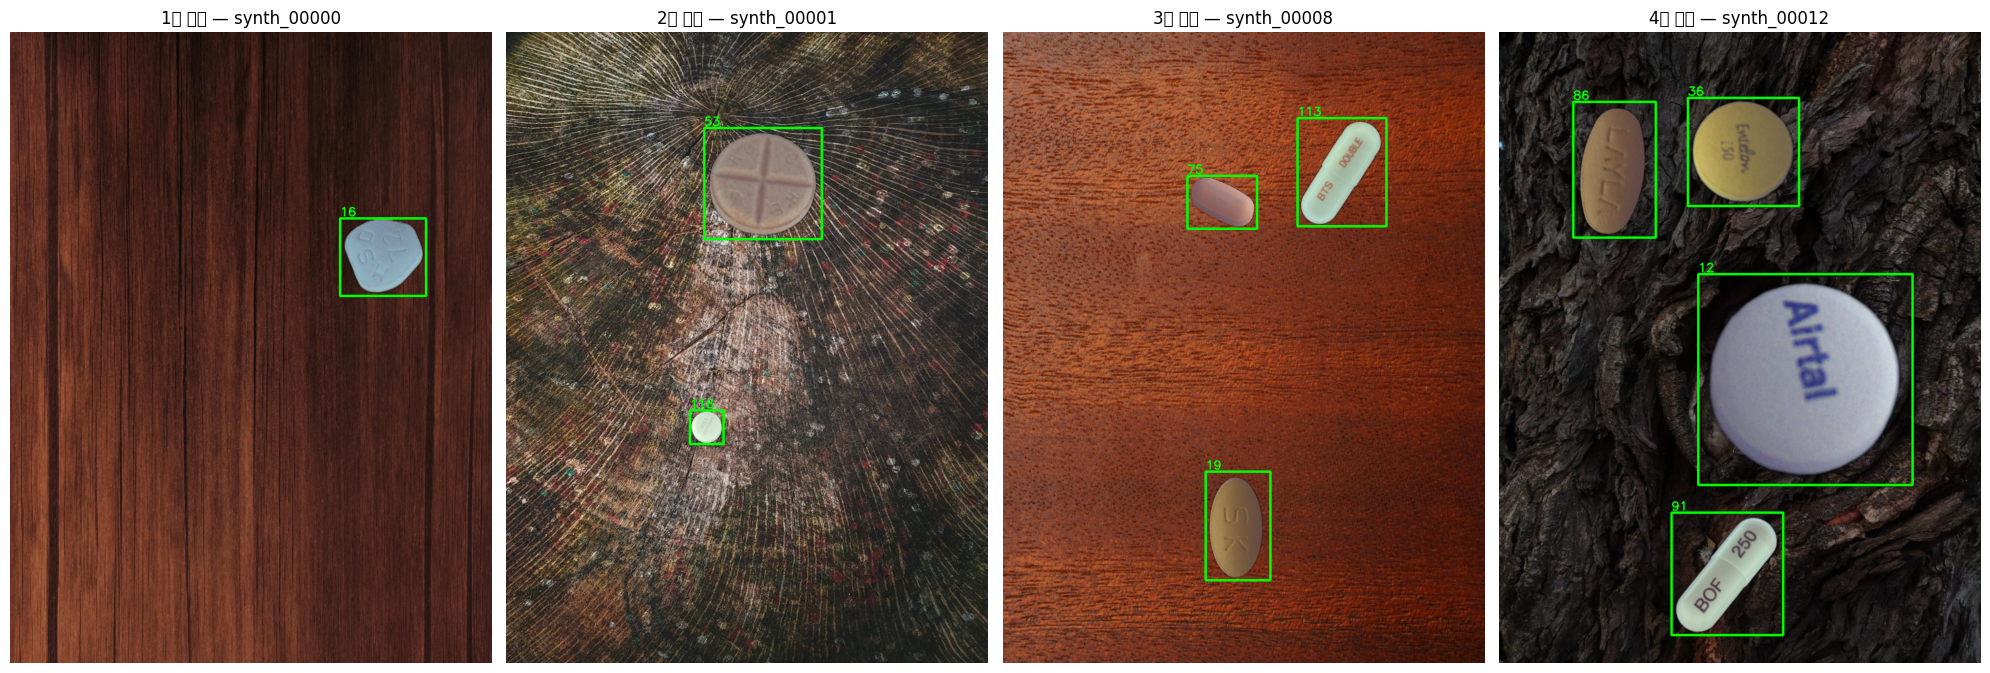

In [21]:
import matplotlib.pyplot as plt

# 알약 개수별로 1장씩 샘플 선택
samples_by_count = {1: None, 2: None, 3: None, 4: None}
for img_path in sorted(SYNTH_IMG_DIR.glob("*.jpg")):
    lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
    if not lbl_path.exists():
        continue
    with open(lbl_path) as f:
        n = len([l for l in f if l.strip()])
    if n in samples_by_count and samples_by_count[n] is None:
        samples_by_count[n] = img_path
    if all(v is not None for v in samples_by_count.values()):
        break

# 시각화
sample_paths = [(n, p) for n, p in samples_by_count.items() if p is not None]
if sample_paths:
    fig, axes = plt.subplots(1, len(sample_paths), figsize=(5 * len(sample_paths), 7))
    if len(sample_paths) == 1:
        axes = [axes]
    
    for ax, (n_pill, img_path) in zip(axes, sample_paths):
        img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]

        lbl_path = SYNTH_LBL_DIR / (img_path.stem + ".txt")
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                cls, cx, cy, bw, bh = parts[0], *map(float, parts[1:5])
                x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
                cv2.putText(img, cls, (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

        ax.imshow(img)
        ax.set_title(f"{n_pill}개 알약 — {img_path.stem}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("생성된 이미지 없음")

## 10. 9:1 분할 (PowerShell 별도 실행)


## 11. zip 압축 (Drive 업로드용)
